# Statistical Analysis

Apply descriptive statistics and statistical measures to better understand sales behavior, variation, and relationships in the cleaned retail dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

regions = pd.read_csv("../../data/processed/Regions_clean.csv")
products = pd.read_csv("../../data/processed/Products_clean.csv")
customers = pd.read_csv("../../data/processed/Customers_clean.csv")
orders = pd.read_csv("../../data/processed/Orders_clean.csv")
order_items = pd.read_csv("../../data/processed/OrderItems_clean.csv")

In [2]:
customers["RegistrationDate"] = pd.to_datetime(customers["RegistrationDate"])
orders["OrderDate"] = pd.to_datetime(orders["OrderDate"])

In [3]:
print("Regions:", regions.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)

Regions: (5, 2)
Products: (100, 7)
Customers: (995, 10)
Orders: (5000, 6)
Order Items: (13346, 6)


In [4]:
completed_orders = orders[
    orders["OrderStatus"] == "Completed"
].copy()

In [5]:
sales = order_items.merge(
    completed_orders,
    on="OrderID",
    how="inner"
)

هنا بنحسب المبيعات

In [6]:
sales["SalesAmount"] = (
    sales["Quantity"]
    * sales["UnitPrice"]
    * (1 - sales["DiscountPercent"] / 100)
)

In [7]:
order_sales = (
    sales.groupby("OrderID")["SalesAmount"]
    .sum()
    .reset_index()
)

In [8]:
order_sales["SalesAmount"].describe()

count     4038.000000
mean      6375.996041
std       5611.178542
min         20.842000
25%       2221.169125
50%       4784.623000
75%       8777.849000
max      42372.998000
Name: SalesAmount, dtype: float64

In [9]:
print("Mean:", order_sales["SalesAmount"].mean())
print("Median:", order_sales["SalesAmount"].median())
print("Standard Deviation:", order_sales["SalesAmount"].std())
print("Variance:", order_sales["SalesAmount"].var())

Mean: 6375.996041480931
Median: 4784.623
Standard Deviation: 5611.178542276121
Variance: 31485324.633299977


## اهم اكتشاف طلع معنا الحين في الاحصاء الوصفي
اهم ملاحظة طلعت مهنا اول شي ان  الـMean أعلى بشكل واضح من Median
وهذا بالغالب معناته أن توزيع قيمة الطلبات مائل لليمين (Right-skewed)
 لأن بعض الطلبات اللي قيمتها مرتفعة  ترفع المتوسط للأعلى وهذا منطقي لان فيه  Max حول 42 ألف و الوسيط بسسس 4.8 آلاف
بعد شي ثاني  الـStandard Deviation تقريبا 5.6 آلاف، وذها كبير طبعا مقارنة بالمتوسط 6.37 آلاف
يعني عندنا تشتت مرتفع نسبيًا في قيمة الطلبات
والطلبات  كلها مو قريبة من نفس القيمة

## Distribution and Skewness

Evaluate the distribution of completed order values and measure its skewness.

In [10]:
skewness = order_sales["SalesAmount"].skew()

print(f"Skewness: {skewness:.3f}")

Skewness: 1.559


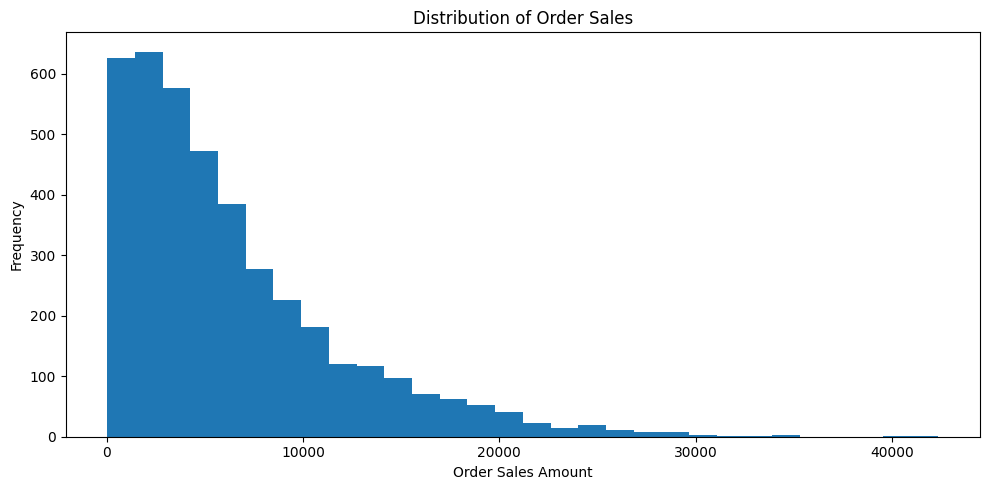

In [11]:
plt.figure(figsize=(10, 5))

plt.hist(
    order_sales["SalesAmount"],
    bins=30
)

plt.title("Distribution of Order Sales")
plt.xlabel("Order Sales Amount")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

## Correlation Analysis

Measure the strength and direction of relationships between numeric sales variables.

In [12]:
correlation = sales[
    ["Quantity", "UnitPrice", "DiscountPercent", "SalesAmount"]
].corr()

correlation

,Quantity,UnitPrice,DiscountPercent,SalesAmount
Quantity,1.000000,-0.002119,0.006711,0.459669
UnitPrice,-0.002119,1.000000,0.010071,0.762997
DiscountPercent,0.006711,0.010071,1.000000,-0.054111
SalesAmount,0.459669,0.762997,-0.054111,1.000000


In [13]:
correlation["SalesAmount"].sort_values(ascending=False)

SalesAmount        1.000000
UnitPrice          0.762997
Quantity           0.459669
DiscountPercent   -0.054111
Name: SalesAmount, dtype: float64

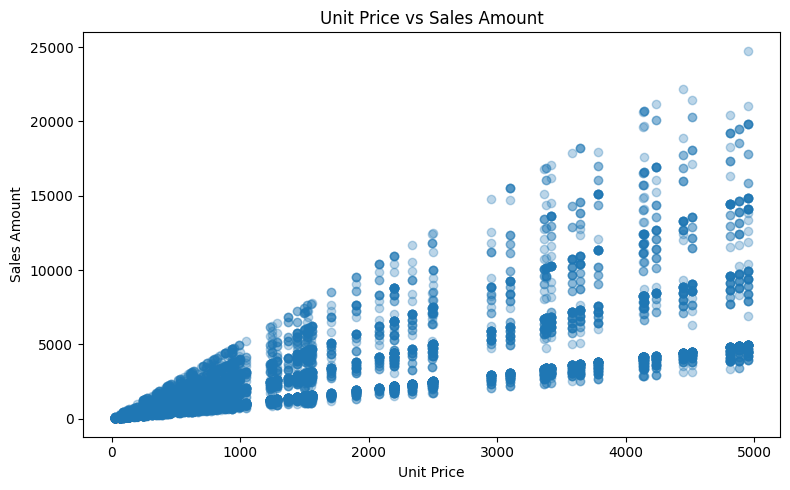

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(
    sales["UnitPrice"],
    sales["SalesAmount"],
    alpha=0.3
)

plt.title("Unit Price vs Sales Amount")
plt.xlabel("Unit Price")
plt.ylabel("Sales Amount")
plt.tight_layout()

plt.show()

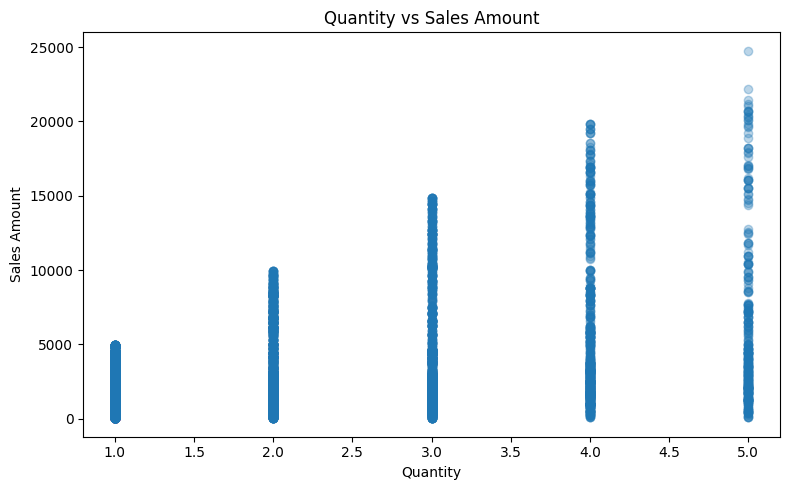

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(
    sales["Quantity"],
    sales["SalesAmount"],
    alpha=0.3
)

plt.title("Quantity vs Sales Amount")
plt.xlabel("Quantity")
plt.ylabel("Sales Amount")
plt.tight_layout()

plt.show()

In [16]:
sales = sales.merge(
    customers[["CustomerID", "CustomerSegment"]],
    on="CustomerID",
    how="left"
)

In [17]:
segment_stats = (
    sales.groupby("CustomerSegment")["SalesAmount"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

segment_stats

,count,mean,median,std
CustomerSegment,,,,
Corporate,933,2602.41,1381.10,3216.95
Premium,2635,2400.74,1337.98,2969.95
Regular,7244,2345.70,1296.42,2918.19


هنا بس نحتاج نثبت مكتبة scipy عشان نشوف موضوع تحليل التابين ANOVA
والهدف منها طبعا نشوف هل الاختلاف في المبيعات بين هذه الشرائح هو اختلاف حقيقي ومهم، أم أنه مجرد صدفة عشوائية؟
" pip install scipy " 
الهدف من المكبتة بس عشان نشوف الشغل بصريا 
طبعا المكتبة هذي مخصصة في العمليات الرياضية والإحصائية المتقدمة

In [18]:
from scipy.stats import f_oneway

In [19]:
regular_sales = sales[
    sales["CustomerSegment"] == "Regular"
]["SalesAmount"]

premium_sales = sales[
    sales["CustomerSegment"] == "Premium"
]["SalesAmount"]

corporate_sales = sales[
    sales["CustomerSegment"] == "Corporate"
]["SalesAmount"]

In [20]:
f_statistic, p_value = f_oneway(
    regular_sales,
    premium_sales,
    corporate_sales
)

print(f"F-statistic: {f_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

F-statistic: 3.1887
P-value: 0.0413


النتيجة اللي وصلنا لها الان انو 0.0413 < 0.05
فنرفض فرضية أن متوسطات الشرائح الثلاث متساوية بالضبط،ونقول
انو يوجد فرق ذو دلالة إحصائية بين متوسطات المبيعات لواحدة على الأقل من شرائح العملاء

والحين بس نبي  نصحح الاختبار قبل ما نروح للـ (Post-hoc)

## ANOVA by Customer Segment

Test whether the mean completed order value differs across customer segments.

In [21]:
order_segment_sales = (
    sales.groupby(["OrderID", "CustomerID"])["SalesAmount"]
    .sum()
    .reset_index()
)

order_segment_sales = order_segment_sales.merge(
    customers[["CustomerID", "CustomerSegment"]],
    on="CustomerID",
    how="left"
)

order_segment_sales.head()

,OrderID,CustomerID,SalesAmount,CustomerSegment
0,2,424,1789.4540,Regular
1,3,660,8370.1975,Regular
2,4,575,5266.7360,Premium
3,5,163,24252.9295,Corporate
4,6,896,1584.4540,Regular


In [22]:
order_segment_sales.groupby("CustomerSegment")["SalesAmount"].agg(
    ["count", "mean", "median", "std"]
).round(2)

,count,mean,median,std
CustomerSegment,,,,
Corporate,342,7099.55,5013.30,6542.80
Premium,992,6376.98,4861.61,5613.11
Regular,2704,6284.12,4741.65,5477.00


In [23]:
regular_sales = order_segment_sales[
    order_segment_sales["CustomerSegment"] == "Regular"
]["SalesAmount"]

premium_sales = order_segment_sales[
    order_segment_sales["CustomerSegment"] == "Premium"
]["SalesAmount"]

corporate_sales = order_segment_sales[
    order_segment_sales["CustomerSegment"] == "Corporate"
]["SalesAmount"]

f_statistic, p_value = f_oneway(
    regular_sales,
    premium_sales,
    corporate_sales
)

print(f"F-statistic: {f_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

F-statistic: 3.2094
P-value: 0.0405


معنى هذا أن متوسط قيمة الطلب يختلف إحصائيًا بين شرائح العملاء الثلاث لكن
ANOVA 
ما يحدد لنا بالضبط أي زوج من الشرائح هو المختلف

عشان كذا نبي ننتقل إلى Tukey HSD كاختبار Post-hoc
ونثبت مكتبة 
" pip install statsmodels " 
ونشوف وش يصير معنا ....

In [24]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [25]:
tukey_result = pairwise_tukeyhsd(
    endog=order_segment_sales["SalesAmount"],
    groups=order_segment_sales["CustomerSegment"],
    alpha=0.05
)

print(tukey_result)

     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
  group1   group2  meandiff p-adj    lower     upper   reject
-------------------------------------------------------------
Corporate Premium -722.5771 0.0996 -1547.0726 101.9184  False
Corporate Regular -815.4332 0.0304 -1570.0524  -60.814   True
  Premium Regular  -92.8561 0.8962  -580.9306 395.2183  False
-------------------------------------------------------------


### خلاصة تحليل التباين (ANOVA) واختبار المقارنات البعدية (Tukey HSD)
أشار اختبار تحليل التباين الأحادي (One-way ANOVA) إلى وجود فروق ذات دلالة إحصائية في متوسط قيمة الطلبات المكتملة بين شرائح العملاء (p = 0.0405).

أظهر تحليل المقارنات البعدية (Tukey HSD) أن الفرق المهم والجوهري كان تحديداً بين شريحة الشركات (Corporate) والشريحة العادية (Regular) بقيمة (p = 0.0304).

لم تُلاحظ أي فروق ذات دلالة إحصائية بين:

شريحة الشركات (Corporate) والشريحة المميزة (Premium)

الشريحة المميزة (Premium) والشريحة العادية (Regular)

### ANOVA and Tukey HSD Conclusion

A one-way ANOVA indicated a statistically significant difference in mean completed order value across customer segments (`p = 0.0405`).

Tukey HSD post-hoc analysis showed that the significant difference was specifically between the `Corporate` and `Regular` segments (`p = 0.0304`).

No statistically significant differences were found between:
- Corporate and Premium
- Premium and Regular

## Chi-Square Test

Test whether there is a statistically significant association between payment method and order status.

In [26]:
contingency_table = pd.crosstab(
    orders["PaymentMethod"],
    orders["OrderStatus"]
)

contingency_table

OrderStatus,Cancelled,Completed,Pending,Returned
PaymentMethod,,,,
Bank Transfer,76,1030,64,65
Card,97,1006,69,87
Cash,93,992,81,86
Digital Wallet,97,1010,62,85


In [27]:
from scipy.stats import chi2_contingency

In [28]:
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Degrees of Freedom: {dof}")

Chi-Square Statistic: 11.1242
P-value: 0.2673
Degrees of Freedom: 9


P-value < 0.05
→ يوجد ارتباط ذو دلالة إحصائية بين PaymentMethod و OrderStatus

P-value >= 0.05
→ لا يوجد دليل كافٍ على وجود ارتباط بينهما

## Statistical Summary

The statistical analysis produced the following key findings:

- Completed order values had a mean of approximately 6,376 and a median of approximately 4,785.
- Order values showed relatively high variability, with a standard deviation of approximately 5,611.
- The order value distribution was positively skewed (`skewness = 1.559`), indicating a smaller number of high-value orders.
- Unit price had a relatively strong positive correlation with sales amount (`r ≈ 0.763`).
- Quantity had a moderate positive correlation with sales amount (`r ≈ 0.460`).
- Discount percentage showed almost no linear correlation with sales amount (`r ≈ -0.054`).
- One-way ANOVA found a statistically significant difference in mean order value across customer segments (`p = 0.0405`).
- Tukey HSD showed that the significant difference was specifically between Corporate and Regular customers (`p = 0.0304`).
- The Chi-Square test found no statistically significant association between payment method and order status (`p = 0.2673`).